# Signale: Zeitbereich vs Frequenzbereich
Ein Signal beschreibt, wie sich ein Parameter auf einen anderen bezieht, beispielsweise der Weg in Bezug zur Zeit. Signale können entweder kontinuierlich (z.B. x(t), y(t)) oder diskret (z.B. x[n], y[n]) sein.

<img src="attachments/zeitVsFreq.png" width="900">

## Signale im Zeitbereich
Im Zeitbereich werden die Werte eines Signals über einen bestimmten Zeitraum angegeben. Signale werden hier üblicherweise mit kleinen Buchstaben, wie y() oder y[], dargestellt. Die Analyse im Zeitbereich konzentriert sich auf Parameter wie Maximum- und Minimumwerte, den Mittelwert, die Standardabweichung, lokale Maxima und Nulldurchgänge. Je nach Fragestellung können zeit- und/oder amplitudenbasierte Analysen relevant sein.

## Signale im Frequenzbereich
Der Frequenzbereich beschreibt die Amplituden der erzeugten Sinus- und Kosinuswellen eines Signals. Signale in diesem Bereich werden typischerweise mit Großbuchstaben, wie Y() oder Y[], symbolisiert.

## Der Zusammenhang zwischen Zeit- und Frequenzbereich
Beide Darstellungen – Zeit- und Frequenzbereich – enthalten die gleichen Informationen, präsentieren diese aber auf unterschiedliche Weise. Eine Umwandlung zwischen diesen Darstellungen ist möglich und erfolgt hauptsächlich mittels der Fourier-Transformation.



## Typische Parameter eines Zeitbereichssignals sind zum Beispiel:

<img src="attachments/zeit.png" width="900">

- Amplitude – maximale Auslenkung des Signals (z. B. in Volt)
- Mittelwert - gibt den durchschnittlichen Wert eines Signals über die Zeit an
- Standardabweichung - misst die Streuung der Werte um den Mittelwert
- Spitzenwert – maximale positive oder negative Auslenkung
- Periodendauer (bei periodischen Signalen) – Dauer eines Zyklus
- Offset (DC-Anteil) – Gleichspannungsanteil des Signals
- Effektivwert (RMS) – quadratischer Mittelwert, wichtig für Leistung
- Signalform – z. B. Sinus, Rechteck, Dreieck
- Anstiegszeit / Abfallzeit – Zeit, die das Signal braucht, um von einem niedrigen auf einen hohen Wert zu wechseln (oder umgekehrt)
- Duty Cycle (Tastverhältnis) - bei periodischen Rechteck- oder Puls-Signalen, wie lange das Signal während einer Periode "ein" (aktiv, high) ist, im Verhältnis zur gesamten Periodendauer.

Das folgende Signal ist gegeben:

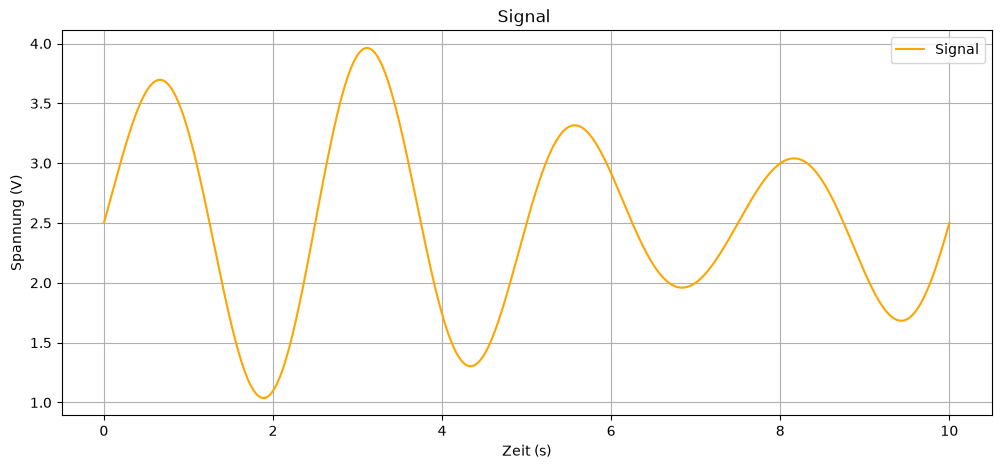

In [3]:
#In[1] Definition of Libraries and Variables
import statistics
import numpy as np
#import mysignals as sig
from matplotlib import pyplot as plt
from matplotlib import style
from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import square
from scipy.ndimage import gaussian_filter1d
# Time vector
t = np.linspace(0, 10, 1000)

# Base signal: 4 oscillations → 4 maxima and 4 minima
base = np.sin(2 * np.pi * 4 * t / max(t))  # 4 cycles

# Amplitude envelope to vary max and min heights
envelope = 1 + 0.5 * np.sin(2 * np.pi * t / max(t))  # slow variation

# Final signal: modulated sine wave
signal = 2.5 + envelope * base

# Plot the signal
plt.style.use('default')
plt.figure(figsize=(12, 5))
plt.plot(t, signal, label="Signal", color='orange')
plt.title("Signal ")
plt.xlabel("Zeit (s)")
plt.ylabel("Spannung (V)")
plt.legend()
plt.grid(True)
plt.show()

**📝 Aufgabe 1:**

- Berechnen Sie mathematisch das Maximum und das Minimum der Funktion
- Zeichnen Sie die lokalen Maxima und Minima mit der Funktion find_peaks auf


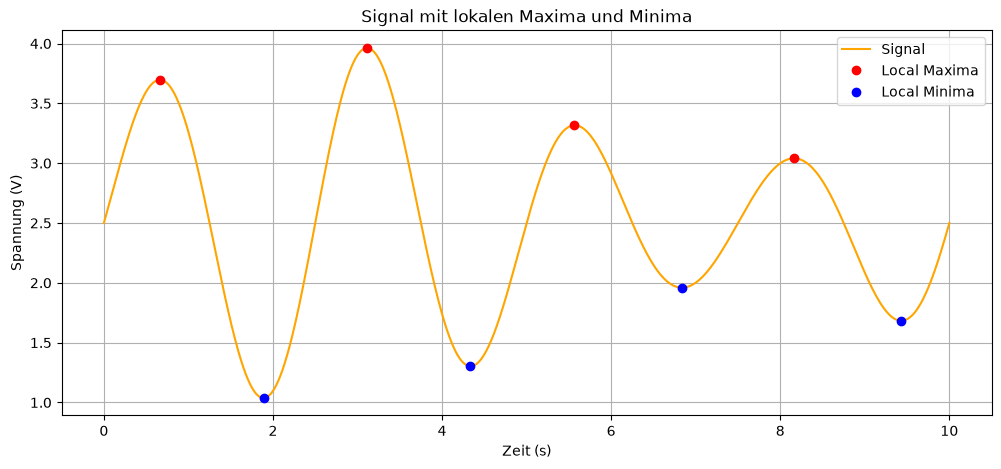

In [4]:
# In[2] Find local maxima using the find_peaks function
peaks_max, _ = find_peaks(signal)
# Find local minima by finding peaks of the inverted signal
peaks_min, _ = find_peaks(-signal)


# Plot the signal
plt.style.use('default')
plt.figure(figsize=(12, 5))
plt.plot(t, signal, label="Signal", color='orange')
plt.plot(t[peaks_max], signal[peaks_max], 'ro', label="Local Maxima")
plt.plot(t[peaks_min], signal[peaks_min], 'bo', label="Local Minima")

plt.title("Signal mit lokalen Maxima und Minima")
plt.xlabel("Zeit (s)")
plt.ylabel("Spannung (V)")
plt.legend()
plt.grid(True)
plt.show()

**📝 Aufgabe 2:**
Gesucht: Mittelwert, Varianz, Standardabweichung, Max, Min

- Schreiben Sie eine Funktion, die diese Rechnungen ausführt ohne die eingebauten Funktionen von Python Bibliotheken zu verwenden

- Verwenden Sie dann die eingebauten Funktionen von Python Bibliotheken und vergleichen Sie den Wert

- Plotten Sie das Signal, Mittelwert, Lokale Max und Min und Max und Min in einem Plot


Der Mittelwert ist: 2.5
Der Mittelwert alt ist: 2.4999999999999982
Die Varianz ist: 0.5625
Die Varianz_alt ist: 0.562499999999999
Die Standardabweichung ist: 0.75
Das Maximum ist: 3.962702967017167
Das Minimum ist: 1.0373745498330134
Der Index des Maximums ist: 311
Der Index des Minimums ist: 189


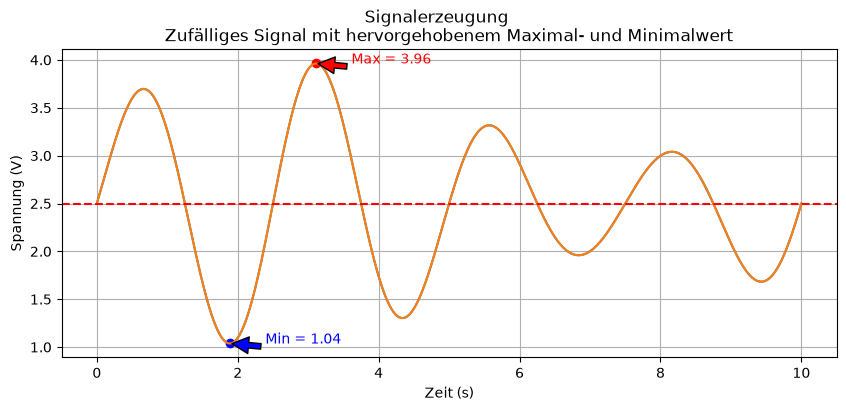

In [6]:
#In[3]
#Mittelwert
mittelwert = statistics.mean(signal)
print("Der Mittelwert ist:", mittelwert)
mittelwert_alt = sum(signal) / len(signal)
print("Der Mittelwert alt ist:", mittelwert_alt)

#Varianz
varianz = statistics.variance(signal) 
abweichungen = [pow((x1 - mittelwert), 2) for x1 in signal]
varianz_alt = sum(abweichungen) / (len(signal) - 1)  
print("Die Varianz ist:", varianz) 
print("Die Varianz_alt ist:", varianz_alt) 

#Standardabweichung
std = statistics.stdev(signal) 
print("Die Standardabweichung ist:", std)

#Max
max_val = max(signal)
print("Das Maximum ist:", max_val)

#Min
min_val = min(signal)
print("Das Minimum ist:", min_val)

# Find the index of the maximum value in y
max_index = np.argmax(signal)
max_time = t[max_index]
# Find the index of the minimum value in y
min_index = np.argmin(signal)
min_time = t[min_index]


print("Der Index des Maximums ist:", max_index)
print("Der Index des Minimums ist:", min_index)

# Plot the signal
plt.figure(figsize=(10, 4))
plt.plot(t, signal, label="Signal")
plt.plot(max_time, max_val, 'ro', label=f"Max = {max_val:.2f}")
plt.annotate(f"Max = {max_val:.2f}", xy=(max_time, max_val),
             xytext=(max_time + 0.5, max_val),
             arrowprops={'facecolor': 'red', 'shrink': 0.05},
             fontsize=10, color='red')
plt.plot(min_time, min_val, 'bo', label=f"Min = {min_val:.2f}")
plt.annotate(f"Min = {min_val:.2f}", xy=(min_time, min_val),
             xytext=(min_time + 0.5, min_val),
             arrowprops={'facecolor': 'blue', 'shrink': 0.05},
             fontsize=10, color='blue')
plt.title("Zufälliges Signal mit hervorgehobenem Maximal- und Minimalwert")
plt.xlabel("Zeit (s)")
plt.ylabel("Spannung (V)")
plt.grid(True)


# Plotting the signal with the mean value line
plt.plot(t,signal)
plt.suptitle('Signalerzeugung')
plt.axhline(mittelwert, color='red', linestyle='--', label='Mittelwert')
plt.show()